In [ ]:
!pip install pgeocode requests openpyxl


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_squared_error, r2_score
import joblib


In [2]:
df = pd.read_excel("/content/Project.xlsx")

In [3]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (492, 12)
Total Rows: 492
Total Columns: 12


In [4]:
df.head()

,pickup_date,package_type,product_value,cod_amount,weight,shipping_charges,destination_pin,product_name,fpd,delivery_days,pickup_month,pickup_day
0,2025-12-09 13:16:27,Pre-paid,307,0,400.0,39.55,325202,Keychains,2025-12-10 03:02:01,0.573310,12,9
1,2025-12-09 13:16:23,COD,248,248,400.0,86.75,322021,Keychains,2025-12-11 04:03:30,1.616053,12,9
2,2026-03-14 13:42:14,COD,1998,1798,510.0,174.09,500002,12 Pair Jhumka Box (2),2026-03-19 08:28:30,4.782130,3,14
3,2026-03-12 09:56:37,COD,409,369,300.0,86.74,462001,Love Pearl Necklace,2026-03-17 04:47:39,4.785440,3,12
4,2026-03-10 09:59:27,COD,409,369,230.0,109.49,844504,Love Pearl Necklace,2026-03-16 03:01:22,5.709664,3,10


In [5]:
df.columns

Index(['pickup_date', 'package_type', 'product_value', 'cod_amount', 'weight',
       'shipping_charges', 'destination_pin', 'product_name', 'fpd',
       'delivery_days', 'pickup_month', 'pickup_day'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 492 entries, 0 to 491
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pickup_date       492 non-null    object 
 1   package_type      492 non-null    object 
 2   product_value     492 non-null    int64  
 3   cod_amount        492 non-null    int64  
 4   weight            492 non-null    float64
 5   shipping_charges  492 non-null    float64
 6   destination_pin   492 non-null    int64  
 7   product_name      492 non-null    object 
 8   fpd               492 non-null    object 
 9   delivery_days     492 non-null    float64
 10  pickup_month      492 non-null    int64  
 11  pickup_day        492 non-null    int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 46.3+ KB


In [7]:

df.describe()

,product_value,cod_amount,weight,shipping_charges,destination_pin,delivery_days,pickup_month,pickup_day
count,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000
mean,412.538618,372.327236,295.453232,106.673008,352536.128049,3.453178,6.077236,20.223577
std,232.792646,167.916672,324.756126,33.333399,178468.120924,1.730364,5.159979,8.683318
min,229.000000,0.000000,60.000000,39.540000,110005.000000,0.477731,1.000000,1.000000
25%,335.000000,335.000000,130.000000,86.750000,249407.000000,2.205078,1.000000,16.750000
50%,359.000000,359.000000,256.055000,109.500000,312601.000000,2.769763,3.000000,22.000000
75%,370.500000,359.000000,300.000000,122.572500,400702.750000,4.685613,12.000000,27.000000
max,3000.000000,1798.000000,3000.000000,322.700000,854330.000000,11.641944,12.000000,31.000000


In [8]:

df.describe(include='object')

,pickup_date,package_type,product_name,fpd
count,492,492,492,492
unique,492,2,21,491
top,2025-12-09 13:16:27,COD,Love Pearl Necklace,2025-12-29 18:29:59
freq,1,471,446,2


(array([447.,  21.,  11.,   8.,   2.,   0.,   1.,   0.,   1.,   1.]),
 array([ 229. ,  506.1,  783.2, 1060.3, 1337.4, 1614.5, 1891.6, 2168.7,
        2445.8, 2722.9, 3000. ]),
 <BarContainer object of 10 artists>)

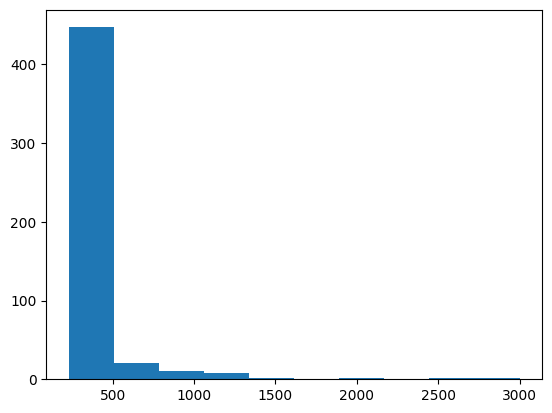

In [9]:
plt.hist(x=df["product_value"])

(array([432.,  35.,   6.,   4.,   3.,   5.,   3.,   2.,   1.,   1.]),
 array([  60.,  354.,  648.,  942., 1236., 1530., 1824., 2118., 2412.,
        2706., 3000.]),
 <BarContainer object of 10 artists>)

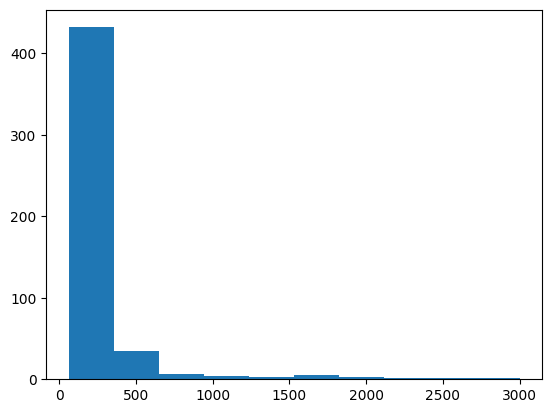

In [10]:
plt.hist(df["weight"])

<Axes: xlabel='count', ylabel='package_type'>

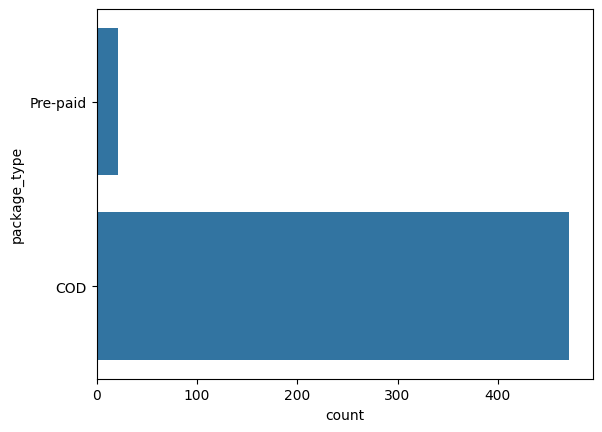

In [11]:
sns.countplot(df["package_type"])

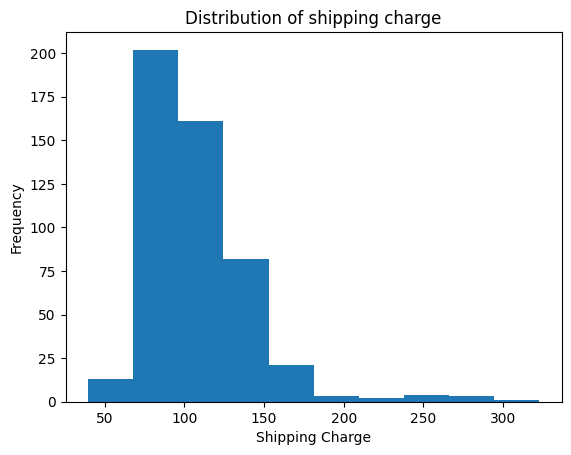

In [12]:
plt.hist(x=df["shipping_charges"])
plt.xlabel("Shipping Charge")
plt.ylabel("Frequency")
plt.title("Distribution of shipping charge")
plt.show()

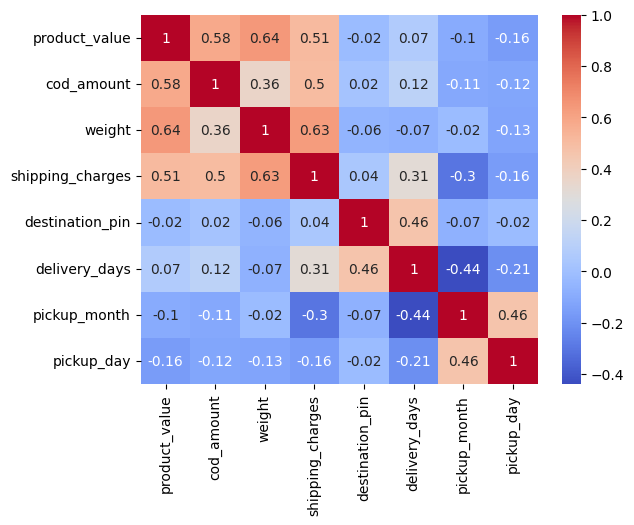

In [13]:
numeric_df = df.select_dtypes(include = "number")
corr = round(numeric_df.corr(), 2)
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

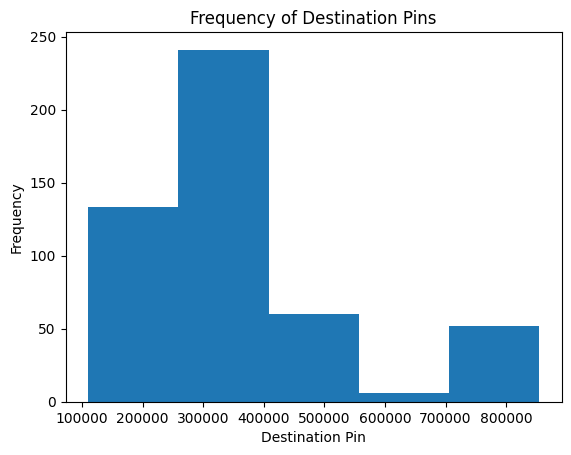

In [14]:
plt.hist(df["destination_pin"], bins=5)
plt.xlabel("Destination Pin")
plt.ylabel("Frequency")
plt.title("Frequency of Destination Pins")
plt.show()

In [ ]:
# Check unique values in important categorical columns

print("Unique Package Types:")
print(df['package_type'].unique())

print("\nUnique Product Names:")
print(df['product_name'].unique())

print("\nTotal Unique Products:")
print(df['product_name'].nunique())

print("\nTotal Unique Destination PINs:")
print(df['destination_pin'].nunique())


Unique Package Types:
['Pre-paid' 'COD']

Unique Product Names:
['Keychains' '12 Pair Jhumka Box (2)' 'Love Pearl Necklace'
 'Special Customised Hamper' 'Love Pearl Necklace~Jhumka box'
 'Love Pearl Necklace(2)' 'Love Pearl Necklace~Heart Box'
 '3D LED Love Miniature Frame' '16 Pair Jhumka Box' 'LED Frame'
 '12 Pair Jhumka Box' '3D Miniature Frame' 'Necklace' 'Gift Hamper'
 'Nova Hair Dryer' 'Acrylic Frame' 'Frame Bedding'
 '3D LED Couple Miniature Frame' 'Heart Box~Couple Music Lamp'
 'Couple Music Lamp' 'Mini Bouquet']

Total Unique Products:
21

Total Unique Destination PINs:
374


In [ ]:
df.tail()

,pickup_date,package_type,product_value,cod_amount,weight,shipping_charges,destination_pin,product_name,fpd,delivery_days,pickup_month,pickup_day
487,2026-04-09 09:54:24,COD,949,949,300.0,89.07,472001,12 Pair Jhumka Box,2026-04-14 04:01:57,4.755243,4,9
488,2026-04-10 09:12:16,COD,1099,1099,550.0,169.31,394650,16 Pair Jhumka Box,2026-04-14 04:13:07,3.792257,4,10
489,2026-04-11 14:10:17,COD,599,599,620.0,169.31,251001,LED Frame,2026-04-15 01:50:35,3.486319,4,11
490,2026-04-07 09:51:26,COD,999,949,500.0,125.03,180004,12 Pair Jhumka Box,2026-04-13 03:32:28,5.736829,4,7
491,2026-04-10 09:12:12,COD,949,949,289.8,89.07,383315,12 Pair Jhumka Box,2026-04-13 04:29:33,2.803715,4,10


In [ ]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

# Display duplicate records if present
df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
)


Total Duplicate Rows: 0


,pickup_date,package_type,product_value,cod_amount,weight,shipping_charges,destination_pin,product_name,fpd,delivery_days,pickup_month,pickup_day


In [ ]:

# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum())


Missing Values:
pickup_date         0
package_type        0
product_value       0
cod_amount          0
weight              0
shipping_charges    0
destination_pin     0
product_name        0
fpd                 0
delivery_days       0
pickup_month        0
pickup_day          0
dtype: int64

Total Missing Values: pickup_date         0
package_type        0
product_value       0
cod_amount          0
weight              0
shipping_charges    0
destination_pin     0
product_name        0
fpd                 0
delivery_days       0
pickup_month        0
pickup_day          0
dtype: int64


In [ ]:

# Convert destination PIN into string

df['destination_pin'] = (df['destination_pin'].astype('string').str.strip())

# Check PIN data type
print("Destination PIN Data Type:", df['destination_pin'].dtype)

# Display sample PINs
print(df['destination_pin'].head())


Destination PIN Data Type: string
0    325202
1    322021
2    500002
3    462001
4    844504
Name: destination_pin, dtype: string


In [ ]:

# Check whether PIN codes contain exactly 6 digits

valid_pin = df['destination_pin'].str.fullmatch(r'\d{6}')

print("Valid PINs:", valid_pin.sum())
print("Invalid PINs:", (~valid_pin).sum())

# Display invalid PIN records
display(df.loc[~valid_pin])


Valid PINs: 492
Invalid PINs: 0


,pickup_date,package_type,product_value,cod_amount,weight,shipping_charges,destination_pin,product_name,fpd,delivery_days,pickup_month,pickup_day


In [ ]:
# Fixed dispatch PIN
SOURCE_PIN = "324007"

# Get unique destination PINs
unique_pins = sorted(df['destination_pin'].unique().tolist())

print("Original Dataset Shape:", df.shape)
print("Total Destination PINs:", len(unique_pins))
print("Source PIN:", SOURCE_PIN)

# Check invalid PINs
invalid_pins = [
    pin for pin in unique_pins
    if len(pin) != 6 or not pin.isdigit()
]

print("Invalid PINs:", invalid_pins)
print("Invalid PIN Count:", len(invalid_pins))

Original Dataset Shape: (492, 12)
Total Destination PINs: 374
Source PIN: 324007
Invalid PINs: []
Invalid PIN Count: 0


In [ ]:
import pgeocode

print("pgeocode version:", pgeocode.__version__)

pgeocode version: 0.5.0


In [ ]:
# Initialize India geocoder
nomi = pgeocode.Nominatim('IN')

# Fetch coordinates for all unique destination PINs
geo_data = nomi.query_postal_code(unique_pins)

# Create coordinate DataFrame
coordinates_df = pd.DataFrame({
    'destination_pin': unique_pins,
    'latitude': geo_data['latitude'].values,
    'longitude': geo_data['longitude'].values
})

# Check results
print("Total PINs:", len(coordinates_df))
print("Missing Latitude:", coordinates_df['latitude'].isna().sum())
print("Missing Longitude:", coordinates_df['longitude'].isna().sum())

print("\nFirst 10 records:")
display(coordinates_df.head(10))

Total PINs: 374
Missing Latitude: 4
Missing Longitude: 4

First 10 records:


,destination_pin,latitude,longitude
0,110005,28.653137,77.188775
1,110006,28.696133,77.210056
2,110009,28.712100,77.206000
3,110025,28.567200,77.272500
4,110031,28.654814,77.275186
5,110034,28.716000,77.142900
6,110037,28.547980,77.113300
7,110038,28.572400,77.027400
8,110042,28.758100,77.130900
9,110043,28.605588,76.994565


In [ ]:
# Find PINs with missing coordinates
missing_coordinates = coordinates_df[
    coordinates_df['latitude'].isna() |
    coordinates_df['longitude'].isna()
]

print("Missing coordinate records:")
display(missing_coordinates)

print("\nMissing PIN list:")
print(missing_coordinates['destination_pin'].tolist())

Missing coordinate records:


,destination_pin,latitude,longitude
58,201302,NaN,NaN
60,202527,NaN,NaN
93,245408,NaN,NaN
220,334301,NaN,NaN



Missing PIN list:
['201302', '202527', '245408', '334301']


In [ ]:
# Manually correct missing PIN coordinates
manual_coordinates = {
    '201302': (28.670200, 77.444500),
    '202527': (28.342580, 78.424250),
    '245408': (28.406971, 77.849821),
    '334301': (28.190500, 73.573800)
}

for pin, (lat, lon) in manual_coordinates.items():
    coordinates_df.loc[
        coordinates_df['destination_pin'] == pin,
        ['latitude', 'longitude']
    ] = [lat, lon]

# Validate missing values
print("Missing Latitude:", coordinates_df['latitude'].isna().sum())
print("Missing Longitude:", coordinates_df['longitude'].isna().sum())

# Display corrected records
display(
    coordinates_df[
        coordinates_df['destination_pin'].isin(manual_coordinates)
    ]
)

Missing Latitude: 0
Missing Longitude: 0


,destination_pin,latitude,longitude
58,201302,28.670200,77.444500
60,202527,28.342580,78.424250
93,245408,28.406971,77.849821
220,334301,28.190500,73.573800


In [ ]:
# Load India PIN coordinates reference CSV
pin_df = pd.read_csv("India_PIN_Coordinates.csv", dtype={"pincode": "string"})

# Clean PIN codes
pin_df['pincode'] = (pin_df['pincode'].str.strip().str.zfill(6))

# Convert coordinates to numeric
pin_df['latitude'] = pd.to_numeric(pin_df['latitude'], errors='coerce')

pin_df['longitude'] = pd.to_numeric(pin_df['longitude'], errors='coerce')

print("Reference CSV Shape:", pin_df.shape)
print("Unique PINs in CSV:", pin_df['pincode'].nunique())

print("Valid coordinate rows:",pin_df[['latitude', 'longitude']].dropna().shape[0])

print("\nFirst 5 records:")
display(pin_df.head())

Reference CSV Shape: (30230, 11)
Unique PINs in CSV: 12757
Valid coordinate rows: 27800

First 5 records:


,circlename,regionname,divisionname,officename,pincode,officetype,delivery,district,statename,latitude,longitude
0,Telangana Circle,Hyderabad Region,Adilabad Division,Kothimir B.O,504273,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.363869,79.537666
1,Telangana Circle,Hyderabad Region,Adilabad Division,Papanpet B.O,504299,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.476490,79.583923
2,Telangana Circle,Hyderabad Region,Adilabad Division,Kukuda B.O,504299,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,NaN,NaN
3,Telangana Circle,Hyderabad Region,Adilabad Division,Bareguda B.O,504296,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.328575,79.476013
4,Telangana Circle,Hyderabad Region,Adilabad Division,Mosam B.O,504296,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.377804,79.616521


In [ ]:
# Find destination PINs available in reference CSV
reference_pins = set(pin_df['pincode'].dropna().unique())

destination_pins = set(coordinates_df['destination_pin'])

matched_pins = destination_pins.intersection(reference_pins)
unmatched_pins = destination_pins - reference_pins

print("Total destination PINs:", len(destination_pins))
print("PINs found in reference CSV:", len(matched_pins))
print("PINs not found in reference CSV:", len(unmatched_pins))

print("\nUnmatched PINs:")
print(sorted(unmatched_pins))

Total destination PINs: 374
PINs found in reference CSV: 261
PINs not found in reference CSV: 113

Unmatched PINs:
['110006', '110031', '110038', '110077', '110078', '122017', '131029', '134003', '134113', '143001', '160055', '176103', '180004', '190001', '201007', '201301', '201302', '202001', '202527', '207001', '208010', '208011', '208027', '209621', '211003', '225003', '226018', '243001', '244251', '245408', '249204', '249407', '250005', '251001', '276123', '276201', '277201', '281001', '282001', '284128', '302001', '302002', '302003', '302004', '302006', '302012', '302015', '302016', '302017', '302019', '302020', '302021', '302031', '302039', '303338', '304804', '305001', '305901', '311001', '312620', '313004', '321606', '322021', '323022', '332001', '332311', '332404', '333042', '334301', '342001', '342006', '362037', '380058', '382213', '384265', '392001', '393002', '394221', '400024', '400092', '400612', '400701', '400708', '401105', '424101', '431005', '431006', '440037', '452

In [ ]:
import requests
import pandas as pd
import time
import numpy as np

# Fixed source PIN
SOURCE_PIN = "324007"

# Get source coordinates
source_geo = nomi.query_postal_code(SOURCE_PIN)

SOURCE_LAT = source_geo.latitude
SOURCE_LON = source_geo.longitude

if pd.isna(SOURCE_LAT) or pd.isna(SOURCE_LON):
    raise ValueError("Source PIN coordinates are missing!")

print("Source PIN:", SOURCE_PIN)
print("Source Latitude:", SOURCE_LAT)
print("Source Longitude:", SOURCE_LON)

# Prepare destination coordinates
destinations = coordinates_df.copy()

destinations['destination_pin'] = (
    destinations['destination_pin'].astype(str)
)

destinations = destinations.sort_values(
    'destination_pin'
).reset_index(drop=True)

# OSRM Table API settings
BASE_URL = "https://router.project-osrm.org/table/v1/driving/"
BATCH_SIZE = 50

road_results = []

# Calculate road distances in batches
for start_idx in range(0, len(destinations), BATCH_SIZE):

    batch = destinations.iloc[
        start_idx:start_idx + BATCH_SIZE
    ]

    # Source coordinate: longitude,latitude
    coordinates = [
        f"{SOURCE_LON},{SOURCE_LAT}"
    ]

    # Add destination coordinates
    for _, row in batch.iterrows():
        coordinates.append(
            f"{row['longitude']},{row['latitude']}"
        )

    # Source is coordinate index 0
    # Destinations are coordinate indices 1 onwards
    destination_indexes = ";".join(
        str(i) for i in range(1, len(coordinates))
    )

    url = BASE_URL + ";".join(coordinates)

    params = {
        "sources": "0",
        "destinations": destination_indexes,
        "annotations": "distance"
    }

    response = None

    # Retry if request fails
    for attempt in range(3):
        try:
            response = requests.get(
                url,
                params=params,
                timeout=60
            )

            response.raise_for_status()
            result = response.json()

            if result.get('code') == 'Ok':
                break

            raise RuntimeError(result.get('code'))

        except Exception as e:
            if attempt == 2:
                raise RuntimeError(
                    f"Batch starting at {start_idx} failed: {e}"
                )

            time.sleep(3 * (attempt + 1))

    # Extract road distances in metres
    distances = result['distances'][0]

    for (_, row), distance_m in zip(
        batch.iterrows(), distances
    ):
        road_results.append({
            'destination_pin': row['destination_pin'],
            'road_distance_km': (
                distance_m / 1000
                if distance_m is not None
                else np.nan
            )
        })

    print(
        f"Completed: {min(start_idx + len(batch), len(destinations))}"
        f"/{len(destinations)}"
    )

    time.sleep(1)

# Create final road distance DataFrame
road_distance_df = pd.DataFrame(road_results)

# Validate results
print("\nTotal destination PINs:", len(road_distance_df))
print(
    "Missing road distances:",
    road_distance_df['road_distance_km'].isna().sum()
)
print(
    "Zero road distances:",
    (road_distance_df['road_distance_km'] == 0).sum()
)

print("\nRoad Distance Statistics:")
display(road_distance_df['road_distance_km'].describe())

print("\nFirst 5 road distances:")
display(road_distance_df.head(5))

Source PIN: 324007
Source Latitude: 25.1901
Source Longitude: 76.1223
Completed: 50/374
Completed: 100/374
Completed: 150/374
Completed: 200/374
Completed: 250/374
Completed: 300/374
Completed: 350/374
Completed: 374/374

Total destination PINs: 374
Missing road distances: 0
Zero road distances: 0

Road Distance Statistics:


,road_distance_km
count,374.000000
mean,656.721621
std,418.448118
min,10.776400
25%,368.498125
50%,533.924850
75%,860.252050
max,2182.153500



First 5 road distances:


,destination_pin,road_distance_km
0,110005,441.3747
1,110006,450.6399
2,110009,457.2303
3,110025,428.6643
4,110031,445.6876


In [ ]:
# Prepare destination coordinate data
geo_merge_df = coordinates_df.rename(columns={
    'latitude': 'destination_latitude',
    'longitude': 'destination_longitude'
})

# Merge road distance
geo_merge_df = geo_merge_df.merge(
    road_distance_df,
    on='destination_pin',
    how='inner',
    validate='one_to_one'
)

# Add fixed source coordinates
geo_merge_df['source_latitude'] = SOURCE_LAT
geo_merge_df['source_longitude'] = SOURCE_LON

# Merge geographic information into original dataset
df['destination_pin'] = df['destination_pin'].astype(str)

df = df.merge(
    geo_merge_df,
    on='destination_pin',
    how='left',
    validate='many_to_one'
)

# Validate merged dataset
geo_columns = [
    'destination_latitude',
    'destination_longitude',
    'source_latitude',
    'source_longitude',
    'road_distance_km'
]

print("Updated Dataset Shape:", df.shape)

print("\nMissing geographic values:")
print(df[geo_columns].isna().sum())

print("\nFirst 5 records:")
display(df.head(5))

Updated Dataset Shape: (492, 17)

Missing geographic values:
destination_latitude     0
destination_longitude    0
source_latitude          0
source_longitude         0
road_distance_km         0
dtype: int64

First 5 records:


,pickup_date,package_type,product_value,cod_amount,weight,shipping_charges,destination_pin,product_name,fpd,delivery_days,pickup_month,pickup_day,destination_latitude,destination_longitude,road_distance_km,source_latitude,source_longitude
0,2025-12-09 13:16:27,Pre-paid,307,0,400.0,39.55,325202,Keychains,2025-12-10 03:02:01,0.573310,12,9,25.086067,76.552533,56.7836,25.1901,76.1223
1,2025-12-09 13:16:23,COD,248,248,400.0,86.75,322021,Keychains,2025-12-11 04:03:30,1.616053,12,9,26.149133,76.429333,138.0229,25.1901,76.1223
2,2026-03-14 13:42:14,COD,1998,1798,510.0,174.09,500002,12 Pair Jhumka Box (2),2026-03-19 08:28:30,4.782130,3,14,17.386200,78.462000,1126.3305,25.1901,76.1223
3,2026-03-12 09:56:37,COD,409,369,300.0,86.74,462001,Love Pearl Necklace,2026-03-17 04:47:39,4.785440,3,12,23.478000,77.396100,321.4322,25.1901,76.1223
4,2026-03-10 09:59:27,COD,409,369,230.0,109.49,844504,Love Pearl Necklace,2026-03-16 03:01:22,5.709664,3,10,25.689689,85.376556,1103.8835,25.1901,76.1223


In [ ]:
# Final dataset validation

print("Original shipment records:", 492)
print("Updated shipment records:", len(df))

print(
    "Duplicate shipment rows:",
    df.duplicated().sum()
)

print(
    "Missing values in entire dataset:",
    df.isna().sum().sum()
)

print("\nFinal columns:")
print(df.columns.tolist())

Original shipment records: 492
Updated shipment records: 492
Duplicate shipment rows: 0
Missing values in entire dataset: 0

Final columns:
['pickup_date', 'package_type', 'product_value', 'cod_amount', 'weight', 'shipping_charges', 'destination_pin', 'product_name', 'fpd', 'delivery_days', 'pickup_month', 'pickup_day', 'destination_latitude', 'destination_longitude', 'road_distance_km', 'source_latitude', 'source_longitude']


In [ ]:
# Save final dataset

df.to_excel("Project_With_Road_Distance_Final.xlsx", index=False)

print("Dataset saved successfully!")
print("File name:", "Project_With_Road_Distance_Final.xlsx")
print("Final shape:", df.shape)

Dataset saved successfully!
File name: Project_With_Road_Distance_Final.xlsx
Final shape: (492, 17)


In [ ]:
# Step 5.1: Inspect dataset

print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nNumerical Column Summary:")
display(df.describe())

print("\nCategorical Column Summary:")
display(df.describe(include='object'))

Dataset Shape: (492, 17)

Column Data Types:
pickup_date               object
package_type              object
product_value              int64
cod_amount                 int64
weight                   float64
shipping_charges         float64
destination_pin           object
product_name              object
fpd                       object
delivery_days            float64
pickup_month               int64
pickup_day                 int64
destination_latitude     float64
destination_longitude    float64
road_distance_km         float64
source_latitude          float64
source_longitude         float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 492 entries, 0 to 491
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   pickup_date            492 non-null    object 
 1   package_type           492 non-null    object 
 2   product_value          492 non-null    i

,product_value,cod_amount,weight,shipping_charges,delivery_days,pickup_month,pickup_day,destination_latitude,destination_longitude,road_distance_km,source_latitude,source_longitude
count,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,492.000000,4.920000e+02,4.920000e+02
mean,412.538618,372.327236,295.453232,106.673008,3.453178,6.077236,20.223577,25.888020,77.598777,598.483298,2.519010e+01,7.612230e+01
std,232.792646,167.916672,324.756126,33.333399,1.730364,5.159979,8.683318,3.212336,4.333351,395.259555,1.635912e-13,2.560557e-13
min,229.000000,0.000000,60.000000,39.540000,0.477731,1.000000,1.000000,13.026900,70.133300,10.776400,2.519010e+01,7.612230e+01
25%,335.000000,335.000000,130.000000,86.750000,2.205078,1.000000,16.750000,24.588109,74.899500,324.488500,2.519010e+01,7.612230e+01
50%,359.000000,359.000000,256.055000,109.500000,2.769763,3.000000,22.000000,26.642625,76.704100,478.096300,2.519010e+01,7.612230e+01
75%,370.500000,359.000000,300.000000,122.572500,4.685613,12.000000,27.000000,28.250837,78.259690,716.585225,2.519010e+01,7.612230e+01
max,3000.000000,1798.000000,3000.000000,322.700000,11.641944,12.000000,31.000000,34.158367,94.233300,2182.153500,2.519010e+01,7.612230e+01



Categorical Column Summary:


,pickup_date,package_type,destination_pin,product_name,fpd
count,492,492,492,492,492
unique,492,2,374,21,491
top,2025-12-09 13:16:27,COD,302012,Love Pearl Necklace,2025-12-29 18:29:59
freq,1,471,7,446,2


In [ ]:
# Save destination PIN coordinates
joblib.dump(coordinates_df, 'pin_coordinates.pkl')

# Save road distance data
joblib.dump(road_distance_df, 'road_distance.pkl')

print("PIN coordinates saved successfully!")
print("Road distance data saved successfully!")

PIN coordinates saved successfully!
Road distance data saved successfully!


In [ ]:
# Check columns that will not be used directly as model features

columns_to_review = [
    'destination_pin',
    'product_name',
    'source_latitude',
    'source_longitude',
    'fpd'
]

print("Columns to review:")
print(df[columns_to_review].head())

print("\nUnique package types:")
print(df['package_type'].unique())

print("\nUnique product names:")
print(df['product_name'].nunique())

Columns to review:
  destination_pin            product_name  source_latitude  source_longitude  \
0          325202               Keychains          25.1901           76.1223   
1          322021               Keychains          25.1901           76.1223   
2          500002  12 Pair Jhumka Box (2)          25.1901           76.1223   
3          462001     Love Pearl Necklace          25.1901           76.1223   
4          844504     Love Pearl Necklace          25.1901           76.1223   

                   fpd  
0  2025-12-10 03:02:01  
1  2025-12-11 04:03:30  
2  2026-03-19 08:28:30  
3  2026-03-17 04:47:39  
4  2026-03-16 03:01:22  

Unique package types:
['Pre-paid' 'COD']

Unique product names:
21


In [ ]:
from sklearn.preprocessing import LabelEncoder
product_encoder = LabelEncoder()
df["product_name"] = product_encoder.fit_transform(df["product_name"])


In [ ]:
# Save Product Encoder
joblib.dump(product_encoder, 'product_encoder.pkl')

print("Product Encoder saved successfully!")

Product Encoder saved successfully!


In [ ]:
print("Product Name Data Type:", df['product_name'].dtype)

print("\nEncoded Product Names:")
print(df['product_name'].value_counts().sort_index())

print("\nNumber of unique encoded products:")
print(df['product_name'].nunique())

Product Name Data Type: int64

Encoded Product Names:
product_name
0       6
1       1
2       3
3       1
4       1
5       6
6       1
7       1
8       1
9       7
10      1
11      2
12      6
13    446
14      2
15      1
16      1
17      2
18      1
19      1
20      1
Name: count, dtype: int64

Number of unique encoded products:
21


In [ ]:
# Check numerical columns
print("Numerical Columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())

# Check categorical columns
print("\nCategorical Columns:")
print(df.select_dtypes(include=['object']).columns.tolist())

Numerical Columns:
['product_value', 'cod_amount', 'weight', 'shipping_charges', 'product_name', 'delivery_days', 'pickup_month', 'pickup_day', 'destination_latitude', 'destination_longitude', 'road_distance_km', 'source_latitude', 'source_longitude']

Categorical Columns:
['pickup_date', 'package_type', 'destination_pin', 'fpd']


In [ ]:
# Step 5.7: Define input features

features = [
    'product_value',
    'weight',
    'product_name',
    'destination_latitude',
    'destination_longitude',
    'road_distance_km'
]

print("Selected Features:")
print(features)

print("\nNumber of Features:", len(features))

Selected Features:
['product_value', 'weight', 'product_name', 'destination_latitude', 'destination_longitude', 'road_distance_km']

Number of Features: 6


In [ ]:
# Save feature columns
joblib.dump(features, 'feature_columns.pkl')
print("Feature columns saved successfully!")

Feature columns saved successfully!


## Shipping Model

In [ ]:
X_shipping = df[features]
y_shipping = df['shipping_charges']
X_train_shipping, X_test_shipping, y_train_shipping, y_test_shipping = train_test_split(X_shipping, y_shipping, test_size=0.2, random_state=42)
shipping_model = RandomForestRegressor(n_estimators=1000, random_state=60)
shipping_model.fit(X_train_shipping, y_train_shipping)
y_pred_shipping = shipping_model.predict(X_test_shipping)
mse = mean_squared_error(y_test_shipping, y_pred_shipping)
r2 = r2_score(y_test_shipping, y_pred_shipping)
rmse = root_mean_squared_error(y_test_shipping, y_pred_shipping)
print(mse)
print(rmse)
print(r2)

246.83063585989706
15.710844530447657
0.8429367971016521


In [ ]:
importance = pd.Series(shipping_model.feature_importances_, index=features)
print(importance.sort_values(ascending=False))

weight                   0.487204
product_value            0.256223
road_distance_km         0.169009
destination_latitude     0.046180
destination_longitude    0.032750
product_name             0.008635
dtype: float64


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error

# Shipping Cost - Training and Testing Scores
shipping_train_pred = shipping_model.predict(X_train_shipping)
shipping_test_pred = shipping_model.predict(X_test_shipping)

print("SHIPPING COST MODEL")
print("Training R2:", r2_score(y_train_shipping, shipping_train_pred))
print("Testing R2:", r2_score(y_test_shipping, shipping_test_pred))


SHIPPING COST MODEL
Training R2: 0.9634757154916619
Testing R2: 0.8429367971016521


## Delivery Model

In [ ]:
X_delivery = df[features]
y_delivery = df['delivery_days']
X_train_delivery, X_test_delivery, y_train_delivery, y_test_delivery = train_test_split(X_delivery, y_delivery, test_size=0.2, random_state=42)
delivery_model = RandomForestRegressor( n_estimators=1000, max_depth=8, min_samples_split=9, min_samples_leaf=8,max_features=0.5, random_state=70)
delivery_model.fit(X_train_delivery, y_train_delivery)
y_pred_delivery = delivery_model.predict(X_test_delivery)
mse = mean_squared_error(y_test_delivery, y_pred_delivery)
r2 = r2_score(y_test_delivery, y_pred_delivery)
rmse = root_mean_squared_error(y_test_delivery, y_pred_delivery)
print(mse)
print(rmse)
print(r2)

1.2949193015797003
1.137945210271435
0.5855264571330232


In [ ]:
importance = pd.Series(delivery_model.feature_importances_, index=features)
print(importance.sort_values(ascending=False))

road_distance_km         0.525337
destination_longitude    0.266629
destination_latitude     0.101500
product_value            0.082810
weight                   0.023584
product_name             0.000140
dtype: float64


In [ ]:

# Delivery Days - Training and Testing Scores
delivery_train_pred = delivery_model.predict(X_train_delivery)
delivery_test_pred = delivery_model.predict(X_test_delivery)

print("\nDELIVERY DAYS MODEL")
print("Training R2:", r2_score(y_train_delivery, delivery_train_pred))
print("Testing R2:", r2_score(y_test_delivery, delivery_test_pred))


DELIVERY DAYS MODEL
Training R2: 0.7321888999659439
Testing R2: 0.5855264571330232


In [ ]:
# Compare actual and predicted values

comparison_df = pd.DataFrame({
    'Actual Shipping Cost': y_test_shipping.values,
    'Predicted Shipping Cost': y_pred_shipping,
    'Actual Delivery Days': y_test_delivery.values,
    'Predicted Delivery Days': y_pred_delivery
})

# Show first 15 predictions
display(comparison_df.head(15))

,Actual Shipping Cost,Predicted Shipping Cost,Actual Delivery Days,Predicted Delivery Days
0,86.75,83.583790,2.716887,3.016745
1,86.75,78.002890,1.681076,2.243040
2,112.46,115.518040,2.708600,2.629272
3,39.55,86.717228,1.756562,2.315333
4,86.75,85.398340,0.852859,1.615581
5,79.07,83.215527,1.715764,2.507332
6,110.65,109.997170,4.727431,5.712549
7,86.75,85.940304,1.661539,2.173843
8,86.74,83.661300,2.724317,2.379373
9,112.46,113.397980,2.611053,2.456775


In [ ]:
import joblib

# Save Shipping Cost Model
joblib.dump(shipping_model, 'shipping_model.pkl')

# Save Delivery Days Model
joblib.dump(delivery_model, 'delivery_model.pkl')

print("Both models saved successfully!")

Both models saved successfully!
